# Metadados das avaliações: filtros e achados

Este notebook complementa o desafio adicional do projeto, que pede para usar informações dos pedidos (nota, período, pedido, entrega e categoria) para melhorar as buscas. Ele tem duas partes:

1. o efeito dos filtros de metadados sobre as avaliações que a busca devolve;
2. dois achados que apareceram ao cruzar o texto das avaliações com os metadados.

Pré-requisitos: `make data`, `make index` e `python -m src.eval.eval_filtros` já executados.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data.load_olist import load_olist

pd.set_option("display.max_colwidth", 110)
IMG = ROOT / "docs" / "imagens"
docs = pd.read_parquet(ROOT / "data" / "processed" / "documents.parquet")
print(len(docs), "avaliações com texto")

42121 avaliações com texto


## 1. O que muda quando a busca usa os filtros

Para cada uma das seis perguntas com recorte do conjunto de avaliação (por exemplo, "problemas nas avaliações nota 1 de cama_mesa_banho"), a mesma busca foi feita com e sem o filtro. A tabela mostra, entre as 8 avaliações devolvidas, quantas pertencem ao recorte pedido.

In [2]:
res = json.loads(sorted((ROOT / "eval" / "results").glob("*_filtros.json"))[-1].read_text())
por_pergunta = pd.DataFrame(res["por_pergunta"])
tabela = por_pergunta.pivot(index="pergunta", columns="modo", values="conformidade").mul(100).round(0)
tabela.columns = [f"% no recorte ({c})" for c in tabela.columns]
tabela

,% no recorte (com filtro),% no recorte (sem filtro)
pergunta,,
F01,100.0,0.0
F02,100.0,50.0
F03,100.0,38.0
F04,100.0,12.0
F05,100.0,0.0
F06,100.0,0.0


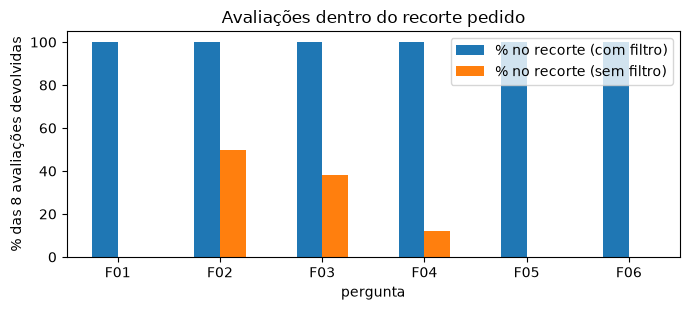

In [3]:
ax = tabela.plot.bar(figsize=(7, 3.2), rot=0)
ax.set_ylabel("% das 8 avaliações devolvidas"); ax.set_xlabel("pergunta"); ax.set_title("Avaliações dentro do recorte pedido")
plt.tight_layout(); plt.savefig(IMG / "filtros_conformidade.png", dpi=120); plt.show()

Sem filtro, só uma pequena parte das avaliações devolvidas pertence ao recorte. Em três perguntas (F01, F05 e F06) nenhuma das 8 está no recorte: a busca encontra reclamações ou elogios parecidos, mas de outras categorias, notas ou faixas de valor. Uma resposta montada com essas avaliações falaria de outro grupo de clientes.

Com o filtro, todas as avaliações estão no recorte, o que é esperado, já que o filtro é aplicado antes da busca. A precisão de relevância das duas configurações, medida pelos julgamentos manuais, está em `eval/results/*_filtros.json`.

## 2. Quando a nota não combina com o texto

Para procurar avaliações em que a nota e o texto dizem coisas diferentes, treinamos um classificador simples (TF-IDF com regressão logística) para distinguir comentários de notas baixas (1 e 2) de comentários de notas altas (4 e 5). As probabilidades vêm de validação cruzada, então cada avaliação é classificada por um modelo que não a viu no treino.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict

polar = docs[docs.review_score.isin([1, 2, 4, 5])].copy()
y = (polar.review_score <= 2).astype(int)
X = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True).fit_transform(polar.texto_normalizado.str.lower())
polar["prob_negativa"] = cross_val_predict(LogisticRegression(max_iter=2000, C=4), X, y, cv=5, method="predict_proba")[:, 1]
print(f"AUC do classificador: {roc_auc_score(y, polar.prob_negativa):.3f}")

AUC do classificador: 0.978


O classificador separa muito bem os dois grupos, então os casos em que ele discorda com muita confiança da nota são bons candidatos a descasamento.

In [5]:
nota5_reclamacao = polar[(polar.review_score == 5) & (polar.prob_negativa > 0.9)]
nota1_elogio = polar[(polar.review_score == 1) & (polar.prob_negativa < 0.1)]
pd.Series({"nota 5 com texto de reclamação": len(nota5_reclamacao), "nota 1 com texto de elogio": len(nota1_elogio)},
          name="avaliações").to_frame()

,avaliações
nota 5 com texto de reclamação,94
nota 1 com texto de elogio,99


In [6]:
nota5_reclamacao.texto_original.head(8).to_frame("nota 5")

,nota 5
1266,Péssima. Recebi o produto que eh falso quero meu dinheiro de volta
1699,targaryen 10. lannister 0. Comprei o produto em Junho. Após pagto disseram q não tinham o produto em estoq...
4067,o produto ainda não chegou apenas a nota fiscal
4782,"Pedi a lapiseira 0,7 recebi 2.0"
5738,Solicitei o cancelamento. Em função da voltagem não ser a da minha região solicitei o cancelamento da comp...
6214,nao foi o esperado. no mostroario e um e o produto e outro
7625,"CEDO AINDA PARA AVALIAR. Comprei 4 kits e só recebi, por enquanto, apenas 01(um). Por isso minha avaliação..."
9005,"Recebi apenas o massageado e, falta um produto"


In [7]:
nota1_elogio[nota1_elogio.n_palavras >= 4].texto_original.head(8).to_frame("nota 1")

,nota 1
3290,"Recomendo a loja. Produto de boa qualidade, entrega dentro do prazo"
3402,"Bom recomendo. Bom produto, recomendo o vendedor. Mais nada pra comentar do produto e do vendedor também."
3409,*****. o produto era exatamente o que eu precisasa
3420,nota 10. vocês e muito pontual
5768,ótimo. Questionamento: o Relogio é a corda?
6211,O cheiro do produto e muito forte! Mas pelo preço não tenho do que reclamar!
8025,"Bom. O produto é bom,só a entrega que demorou"
8324,Otima. Muito Agel com a entrega obrigado


São poucos casos (menos de 1% em cada grupo), mas eles existem: "Recebi o produto que é falso, quero meu dinheiro de volta" com nota 5, ou "Produto de boa qualidade, entrega dentro do prazo" com nota 1. Uma explicação provável é que parte dos clientes confunde a escala.

Para o projeto, isso mostra que o filtro por nota é útil, mas não é perfeito: uma pergunta sobre "reclamações nas avaliações nota 5" pode encontrar reclamações de verdade. Por isso a resposta sempre se baseia no texto das avaliações, e a nota é usada como recorte, não como prova.

## 3. Clientes que respondem à pesquisa antes de receber o produto

Na Olist, a pesquisa de satisfação é enviada ao cliente perto da data de entrega. Vamos comparar a data em que o cliente respondeu com a data em que o pedido foi entregue.

In [8]:
t = load_olist(ROOT / "data" / "raw")
r = t["reviews"].merge(t["orders"][["order_id", "order_delivered_customer_date", "order_estimated_delivery_date"]], on="order_id")
entregues = r[r.order_delivered_customer_date.notna()].copy()
entregues["respondeu_antes"] = entregues.review_answer_timestamp < entregues.order_delivered_customer_date
envio = (entregues.review_creation_date.dt.normalize()
         - entregues[["order_delivered_customer_date", "order_estimated_delivery_date"]].min(axis=1).dt.normalize()).dt.days
print("dias entre min(entrega, data prevista) e o envio da pesquisa (mediana):", envio.median())
print(f"responderam antes da entrega: {entregues.respondeu_antes.mean():.1%} ({entregues.respondeu_antes.sum():,} avaliações)")

dias entre min(entrega, data prevista) e o envio da pesquisa (mediana): 1.0
responderam antes da entrega: 5.0% (4,795 avaliações)


In [9]:
comparacao = entregues.groupby("respondeu_antes").review_score.agg(["count", "mean"]).round(2)
comparacao.index = comparacao.index.map({False: "respondeu depois da entrega", True: "respondeu antes da entrega"})
comparacao.columns = ["avaliações", "nota média"]
comparacao

,avaliações,nota média
respondeu_antes,,
respondeu depois da entrega,91564,4.28
respondeu antes da entrega,4795,1.80


A pesquisa sai, em geral, um dia depois da entrega **ou** da data prevista, o que vier primeiro. Quando o pedido atrasa, a pesquisa chega antes do produto, e o cliente responde ainda sem ter recebido. Isso explica por que esse grupo (cerca de 5% das avaliações) tem nota média muito mais baixa: são, na prática, clientes com o pedido atrasado.

Esse comportamento é efeito do processo de envio da pesquisa, e não um padrão de comportamento do cliente. Ele também reforça o uso do metadado de atraso nas buscas: uma parte importante das reclamações vem de quem ainda estava esperando o produto.

## 4. Resumo

- Sem filtros, a maior parte das avaliações devolvidas pela busca está fora do recorte que a pergunta pede; com filtros, todas estão dentro.
- Existem avaliações em que nota e texto não combinam (menos de 1%), então a nota serve para recortar, mas a resposta deve vir do texto.
- Cerca de 5% dos clientes respondem antes de receber o produto, porque a pesquisa é enviada na data prevista quando o pedido atrasa; esse grupo tem nota média 1,8.